In [1]:
import numpy as np
import pandas as pd

from MetricsRecorder import MetricsRecorder
from Policy import FIFOPolicy, XGBPolicy, GreedyPolicy, GreedyPolicyV2
from ScoringConfig import ScoringConfig
from SimulationConfig import SimulationConfig
from Sim import run_simulation
from DataUtility import summary_average_runs, compare_policies

In [2]:
config = SimulationConfig()
scoring = ScoringConfig()
config.rand_seed = 40
config.mission_duration = 100
n = 5
policies = [XGBPolicy(), FIFOPolicy(), GreedyPolicy(scoring), GreedyPolicyV2(scoring)]
bandwidths = [1, 2, 5, 10]

,bandwidth,total_images_captured,total_images_finalized,total_images_delivered,total_images_deleted,total_available_true_value,total_delivered_value,total_value_loss,normalized_delivered_value,oracle_delivered_value,oracle_regret,normalized_oracle_regret,total_contacts,total_available_downlink_mb,total_transmitted_mb,average_downlink_delay_days,bandwidth_utilization,value_per_mb,runtime_seconds,policy_name
0,1,1200.0,1200.0,1199.4,0.0,1800.2,710.60,1089.60,0.395602,NaN,NaN,NaN,720.0,54000.0,29499.063672,0.084664,0.546167,0.024132,0.459566,xgb
1,1,1200.0,1200.0,0.0,1145.4,1793.0,0.00,1793.00,0.000000,NaN,NaN,NaN,720.0,54000.0,0.000000,NaN,0.000000,0.000000,0.028946,fifo
2,1,1200.0,1200.0,1200.0,0.0,1792.2,448.05,1344.15,0.250000,NaN,NaN,NaN,720.0,54000.0,8105.854883,0.067530,0.150013,0.055136,0.017348,greedy
3,1,1200.0,1200.0,1199.4,0.0,1799.6,794.55,1005.05,0.442169,NaN,NaN,NaN,720.0,54000.0,33255.866797,0.091667,0.616942,0.023861,0.017602,greedy_v2
4,2,1200.0,1200.0,1200.0,0.0,1800.2,1061.65,738.55,0.589154,NaN,NaN,NaN,720.0,108000.0,68172.516406,0.070776,0.631127,0.015553,0.546998,xgb
5,2,1200.0,1200.0,0.0,1145.4,1793.0,0.00,1793.00,0.000000,NaN,NaN,NaN,720.0,108000.0,0.000000,NaN,0.000000,0.000000,0.030956,fifo
6,2,1200.0,1200.0,1200.0,0.0,1792.2,448.05,1344.15,0.250000,NaN,NaN,NaN,720.0,108000.0,8105.854883,0.067098,0.075007,0.055136,0.018502,greedy
7,2,1200.0,1200.0,1200.0,0.0,1799.6,1190.60,609.00,0.660802,NaN,NaN,NaN,720.0,108000.0,70811.676562,0.070862,0.654898,0.016794,0.018353,greedy_v2
8,5,1200.0,1200.0,1200.0,0.0,1800.2,1394.95,405.25,0.775792,NaN,NaN,NaN,720.0,270000.0,110426.348437,0.069043,0.409966,0.012612,0.680016,xgb
9,5,1200.0,1200.0,943.4,204.8,1793.0,1411.20,381.80,0.787359,NaN,NaN,NaN,720.0,270000.0,209475.012500,3.914861,0.775939,0.006762,0.028358,fifo


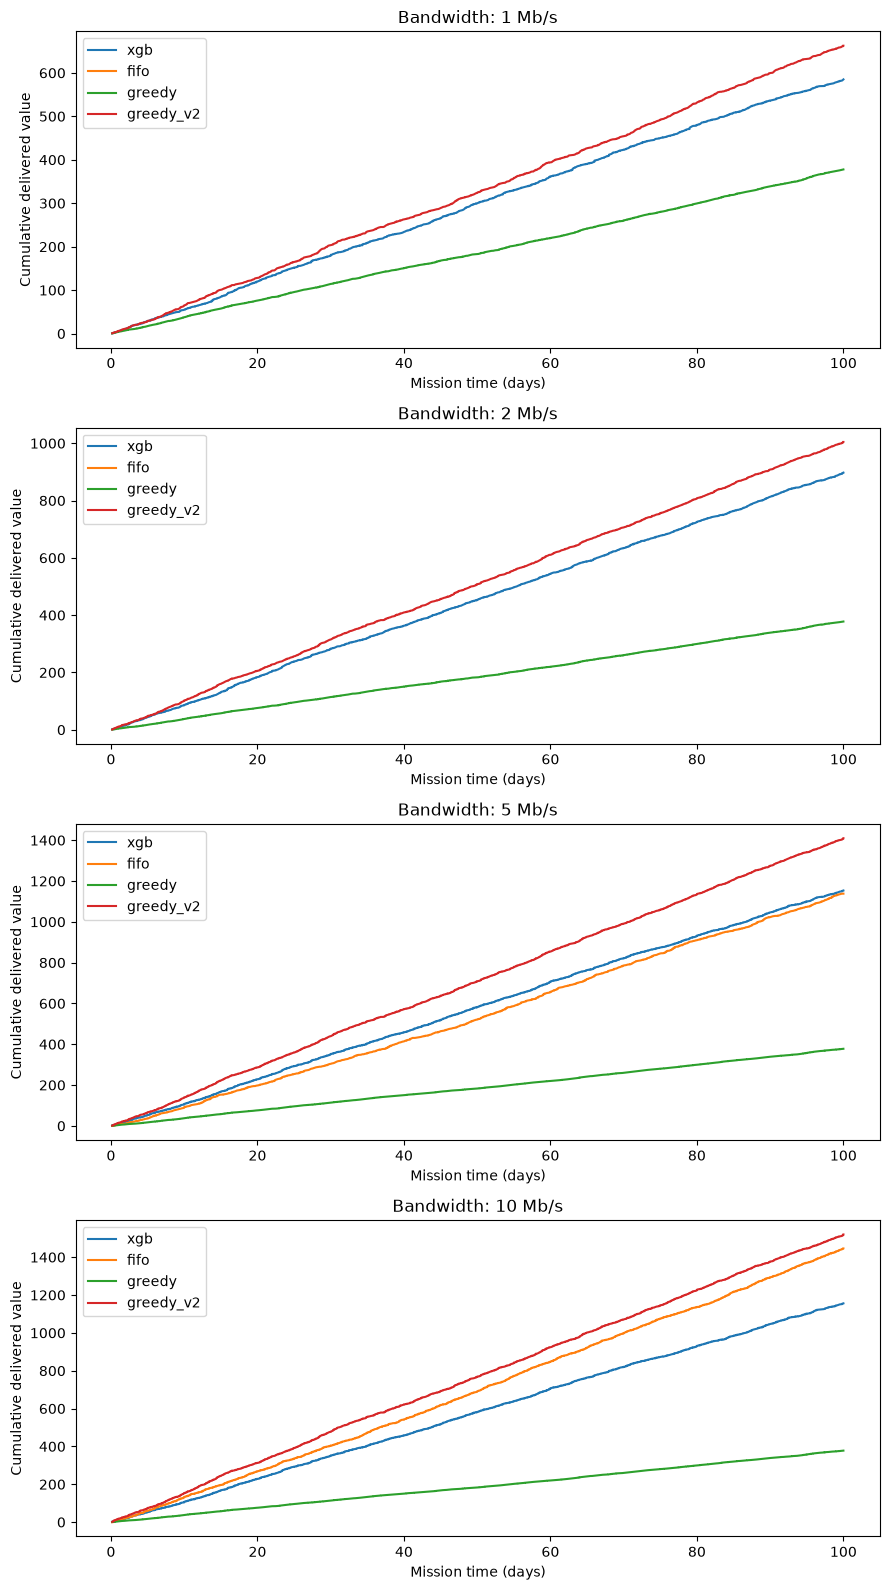

In [3]:
averages, fig, axes = compare_policies(config, policies, scoring, bandwidths, n)
display(averages)  

In [ ]:
"""
if images onboard stored with queue, no need to order in FIFO policy so runtime would improve immensely
XGB is trained on states from FIFO in which performance may drop in non FIFO states, consider training on 
    greedy data or even XGB data.
Optimize XGB? less candidates (filter somehow)??

""""